# Multi-Agent Financial Analysis and Investment Research System
**AAI-520 | Team 7 | Team members: Amit Vishwakarma and Rajkumar T**  
**Data source:** Yahoo Finance via `yfinance`  
**GitHub repository:** `https://github.com/vishwakarmaamit1/aai-520-nlp_and_gen_ai_final_project`

This notebook demonstrates planning, dynamic tool use, specialist routing, news prompt chaining, report synthesis, evaluator–optimizer iteration, and persistent memory. It is an educational prototype, not financial advice.

## 1. Agent Design and Workflows — Requirements and Architecture

| Rubric requirement | Implementation |
|---|---|
| Plan research steps | `PlannerAgent` |
| Use tools dynamically | `ToolRegistry` + orchestrator |
| Self-reflect | `EvaluatorAgent` |
| Learn across runs | JSON-backed `MemoryAgent` |
| Prompt chaining | Ingest → Preprocess → Classify → Extract → Summarize |
| Routing | Router chooses Market, Financial, or News specialist |
| Evaluator–Optimizer | Generate → Evaluate → Refine |

**Architecture:** User → Planner → Router → Market / Financial / News specialists → Synthesis → Evaluator → Optimizer when needed → Memory → Report.

The agents use transparent Python logic and do not require a paid LLM API key. This is an agentic workflow prototype, not an LLM-based autonomous agent.

### Detailed design rationale

The system separates the research task into small responsibilities so each component has a clear input and output. The Planner describes the work to perform; the Tool Registry provides controlled access to data functions; the Router selects a specialist; and the Synthesis Agent combines results into one report. This modular design makes it easier to test a component independently and to identify which stage failed.

**Information flow**
1. The user supplies a ticker symbol and analysis period.
2. The Planner validates the ticker and creates a research plan.
3. The orchestrator follows the plan and calls the registered tools.
4. The Router sends each task to the Market, Financial, or News specialist.
5. The specialists produce structured results.
6. The Synthesis Agent prepares a readable report.
7. The Evaluator checks report completeness and the Optimizer adds feedback when needed.
8. The Memory Agent stores a brief record for future runs.

**Design boundary:** This implementation uses Python rules and programmatic orchestration. It demonstrates the requested agent functions and workflow patterns, but it does not use an LLM to autonomously reason or generate every action. This distinction should be stated clearly in the submission.

## 2. Import dependencies

In [1]:
import json, re
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

pd.set_option("display.max_columns", 30)
MEMORY_PATH = Path("research_memory.json")
SYMBOL = "NVDA"  # Change to AAPL, MSFT, GOOGL, TCS.NS, etc.
PERIOD = "1y"
print("Ready:", SYMBOL)

Ready: NVDA


## 3. Tool layer — Yahoo Finance
The registry enables agents to invoke data tools by name. Data retrieval errors are recorded instead of inventing values.

In [2]:
class YahooFinanceTools:
    def history(self, symbol, period="1y"):
        data = yf.Ticker(symbol).history(period=period, auto_adjust=False)
        if data is None or data.empty:
            raise ValueError(f"No price history returned for {symbol}")
        return data

    def company_info(self, symbol):
        try:
            return yf.Ticker(symbol).info or {}
        except Exception as exc:
            return {"_error": str(exc)}

    def statements(self, symbol):
        ticker = yf.Ticker(symbol)
        output = {}
        for key, attr in [("income_statement", "income_stmt"),
                          ("balance_sheet", "balance_sheet"), ("cash_flow", "cashflow")]:
            try:
                output[key] = getattr(ticker, attr)
            except Exception:
                output[key] = pd.DataFrame()
        return output

    def news(self, symbol):
        try:
            return yf.Ticker(symbol).news or []
        except Exception as exc:
            return [{"_error": str(exc)}]


class ToolRegistry:
    def __init__(self, source):
        self.tools = {"history": source.history, "company_info": source.company_info,
                      "statements": source.statements, "news": source.news}

    def call(self, name, **kwargs):
        if name not in self.tools:
            raise KeyError(f"Unregistered tool: {name}")
        print(f"[Tool] {name}")
        return self.tools[name](**kwargs)


tools = ToolRegistry(YahooFinanceTools())
print("Registered:", list(tools.tools))

Registered: ['history', 'company_info', 'statements', 'news']


## 4. Agent Functions and Capabilities — Planner Agent
The planner creates a stock-specific research plan before execution.

### Planner Agent — detailed explanation

The Planner converts the user's ticker into a sequence of research tasks. Each task identifies a step number, specialist, tool, and purpose. This gives the orchestrator an explicit plan to execute rather than making data requests in an undocumented order.

**Why it matters:** A visible plan improves reproducibility and makes it possible to audit which data sources were requested. The current plan is template-based; it does not dynamically change its steps based on findings from earlier steps. A future enhancement could add conditional steps, such as retrieving additional financial fields when core metrics are missing.

### Dynamic tool use

The Tool Registry maps tool names to Python functions. The orchestrator invokes a tool based on the current plan step. This is dynamic selection from a predefined set of allowed tools, not unrestricted execution of arbitrary external code.

**Benefits:** centralizes data access, makes tool calls traceable, and simplifies error handling.  
**Limitations:** Yahoo Finance can change response schemas, return incomplete fields, or throttle requests. A missing field must remain missing rather than being replaced with an invented value.

### Self-reflection and persistent memory

The Evaluator checks structural completeness and returns feedback. The Optimizer uses this feedback to add follow-up items and a review note. The Memory Agent stores a short run summary and retrieves previous notes for the same ticker.

This is a lightweight self-review and memory mechanism. The system does not update model weights or learn a new predictive model from past runs. Future work could use evaluation history to identify repeated failures and adjust research plans.

In [3]:
class PlannerAgent:
    def plan(self, symbol):
        symbol = symbol.strip().upper()
        if not re.fullmatch(r"[A-Z0-9.^=_-]{1,20}", symbol):
            raise ValueError("Invalid ticker symbol")
        return [
            {"step": 1, "specialist": "market", "tool": "history", "purpose": "Analyze historical price and returns"},
            {"step": 2, "specialist": "financial", "tool": "company_info", "purpose": "Retrieve company profile and key metrics"},
            {"step": 3, "specialist": "financial", "tool": "statements", "purpose": "Check financial statements"},
            {"step": 4, "specialist": "news", "tool": "news", "purpose": "Process recent news headlines"},
        ]

planner = PlannerAgent()
pd.DataFrame(planner.plan(SYMBOL))

,step,specialist,tool,purpose
0,1,market,history,Analyze historical price and returns
1,2,financial,company_info,Retrieve company profile and key metrics
2,3,financial,statements,Check financial statements
3,4,news,news,Process recent news headlines


## 5. Specialist agents — market and financial analysis

### Specialist responsibilities and expected outputs

**Market Agent**
- Calculates the latest and first closing prices in the retrieved period.
- Calculates period return from those two observations.
- Estimates annualized historical volatility from daily percentage returns.
- Calculates 20- and 50-observation moving averages when enough observations exist.
- Retains the underlying price history for visualization.

**Financial Agent**
- Selects available company profile and financial metric fields from the returned company information.
- Checks whether income statement, balance sheet, and cash-flow data are available.
- Reports availability instead of assuming that every company provides every field.

**News Agent**
- Converts available news records into a consistent structure.
- Applies transparent keyword rules to classify topic and sentiment.
- Extracts simple numeric mentions and checks whether the ticker appears in the text.
- Summarizes the resulting records.

**Cross-agent integration:** The agents produce complementary evidence. Market history describes price behavior, financial indicators describe selected company metrics, and news provides a limited view of recent headlines. None of these sources alone is sufficient to make a reliable investment decision.

In [4]:
class MarketAgent:
    def analyze(self, symbol, history):
        col = "Adj Close" if "Adj Close" in history.columns else "Close"
        close = pd.to_numeric(history[col], errors="coerce").dropna()
        if len(close) < 2:
            raise ValueError("Not enough closing-price observations")
        returns = close.pct_change().dropna()
        return {
            "symbol": symbol, "latest_close": float(close.iloc[-1]),
            "period_start_close": float(close.iloc[0]),
            "period_return_pct": float((close.iloc[-1] / close.iloc[0] - 1) * 100),
            "annualized_volatility_pct": float(returns.std() * np.sqrt(252) * 100),
            "moving_average_20": float(close.tail(20).mean()) if len(close) >= 20 else None,
            "moving_average_50": float(close.tail(50).mean()) if len(close) >= 50 else None,
            "observations": int(len(close)), "history": history
        }


class FinancialAgent:
    def analyze(self, info, statements):
        keys = ["longName", "sector", "industry", "currency", "marketCap", "trailingPE",
                "forwardPE", "priceToBook", "profitMargins", "revenueGrowth", "returnOnEquity",
                "debtToEquity", "currentRatio", "freeCashflow", "totalRevenue", "netIncomeToCommon"]
        summary = {k: info[k] for k in keys if info.get(k) is not None}
        availability = {}
        for name in ("income_statement", "balance_sheet", "cash_flow"):
            frame = statements.get(name, pd.DataFrame())
            availability[name] = bool(isinstance(frame, pd.DataFrame) and not frame.empty)
        return {"company_summary": summary, "statement_availability": availability,
                "limitation": "Yahoo Finance fields may be missing or delayed."}

## 6. Prompt chaining — news workflow

The stages are implemented in order: **Ingest → Preprocess → Classify → Extract → Summarize**. The keyword-based classification is a simple baseline and may misinterpret context, negation, or sarcasm.

### Prompt-chain stage details

**1. Ingest:** accepts the news records returned by the source and extracts title, summary, publisher, and link when available. Records without usable titles or records containing retrieval errors are skipped.

**2. Preprocess:** normalizes whitespace and creates a combined text field. This makes later rules more consistent, but it does not perform advanced language normalization, entity resolution, or duplicate detection.

**3. Classify:** compares words in the text with predefined topic and sentiment vocabularies. The category with the highest keyword overlap is selected; if there is no match, the article is labelled general. Sentiment is positive, negative, or neutral according to the balance of matched words.

**4. Extract:** collects simple numeric expressions such as percentages or dollar amounts and checks for the ticker symbol. These are pattern-based extractions, not a full named-entity or financial-event extraction model.

**5. Summarize:** reports the article count, sentiment counts, and a short list of headlines with category, publisher, and link.

**Quality caveat:** Keyword rules can miss negation (for example, “not strong”), distinguish neither fact from opinion nor cause from correlation, and can misclassify context. For a stronger version, compare these labels with a validated financial-news sentiment model and manually reviewed examples.

In [5]:
class NewsAgent:
    positive = {"growth", "record", "beats", "beat", "surge", "rises", "profit", "upgrade", "strong", "expands"}
    negative = {"loss", "miss", "misses", "decline", "falls", "drop", "lawsuit", "warning", "downgrade", "weak"}
    categories = {
        "earnings": {"earnings", "revenue", "profit", "eps", "quarter", "forecast"},
        "market": {"shares", "stock", "market", "price", "trading", "analyst"},
        "product": {"product", "launch", "release", "chip", "service", "technology"},
        "regulatory": {"regulator", "lawsuit", "court", "antitrust", "investigation"},
    }

    def ingest(self, raw):
        rows = []
        for item in raw or []:
            if not isinstance(item, dict) or item.get("_error"):
                continue
            content = item.get("content", item)
            if not isinstance(content, dict):
                content = item
            title = content.get("title") or item.get("title") or ""
            summary = content.get("summary") or item.get("summary") or ""
            provider = content.get("provider")
            publisher = provider.get("displayName") if isinstance(provider, dict) else item.get("publisher", "Unknown")
            canonical = content.get("canonicalUrl")
            link = canonical.get("url") if isinstance(canonical, dict) else item.get("link", "")
            if title.strip():
                rows.append({"title": title.strip(), "summary": summary.strip(),
                             "publisher": publisher or "Unknown", "link": link or ""})
        return rows

    def preprocess(self, rows):
        result = []
        for row in rows:
            title = re.sub(r"\s+", " ", row["title"]).strip()
            summary = re.sub(r"\s+", " ", row["summary"]).strip()
            result.append({**row, "title": title, "summary": summary, "text": (title + ". " + summary).lower()})
        return result

    def classify(self, rows):
        result = []
        for row in rows:
            words = set(re.findall(r"[a-z]+", row["text"]))
            scores = {cat: len(words & terms) for cat, terms in self.categories.items()}
            category = max(scores, key=scores.get)
            if scores[category] == 0:
                category = "general"
            pos, neg = len(words & self.positive), len(words & self.negative)
            sentiment = "positive" if pos > neg else "negative" if neg > pos else "neutral"
            result.append({**row, "category": category, "sentiment": sentiment})
        return result

    def extract(self, rows, symbol):
        result = []
        for row in rows:
            numbers = re.findall(r"(?<!\w)(?:\$\s?\d+(?:\.\d+)?%?|\d+(?:\.\d+)?%)", row["text"])
            result.append({**row, "numeric_mentions": numbers[:10],
                           "ticker_mentioned": symbol.upper() in row["text"].upper()})
        return result

    def summarize(self, rows):
        counts = pd.Series([r["sentiment"] for r in rows], dtype="object").value_counts().to_dict()
        headlines = [{k: r[k] for k in ("title", "category", "sentiment", "publisher", "link")} for r in rows[:8]]
        return {"news_count": len(rows), "sentiment_counts": counts, "headlines": headlines,
                "note": "Sentiment labels are rule-based and indicative only."}

    def run_chain(self, raw, symbol):
        ingested = self.ingest(raw)
        preprocessed = self.preprocess(ingested)
        classified = self.classify(preprocessed)
        extracted = self.extract(classified, symbol)
        return {"stage_counts": {"ingested": len(ingested), "preprocessed": len(preprocessed),
                                 "classified": len(classified), "extracted": len(extracted)},
                "records": extracted, "summary": self.summarize(extracted)}

news_agent = NewsAgent()
print("News chain: Ingest → Preprocess → Classify → Extract → Summarize")

News chain: Ingest → Preprocess → Classify → Extract → Summarize


## 7. Routing agent
The router sends each plan task to its assigned specialist.

### Routing behavior

The Router uses the `specialist` field in each plan task to select the matching specialist object. Market-history tasks go to the Market Agent, company profile and statements go to the Financial Agent, and news tasks go to the News Agent.

The router raises an error for an unknown specialist instead of silently choosing a default. This fail-fast behavior helps identify a planning or configuration problem early.

**Current limitation:** Routing is based on predefined labels in the plan, not on semantic classification of arbitrary user questions. A future version could add intent classification and route earnings-related requests to a dedicated earnings specialist.

In [6]:
class RouterAgent:
    def __init__(self, market, financial, news):
        self.specialists = {"market": market, "financial": financial, "news": news}
    def route(self, task):
        name = task["specialist"]
        if name not in self.specialists:
            raise ValueError(f"No specialist: {name}")
        print(f"[Router] step {task['step']} → {name}")
        return self.specialists[name]

market_agent = MarketAgent()
financial_agent = FinancialAgent()
router = RouterAgent(market_agent, financial_agent, news_agent)

## 8. Memory agent
The JSON-backed memory stores brief notes for later runs. This is persistent note-taking, not model-weight training.

### Memory schema and behavior

For each ticker, the JSON memory keeps a limited list of recent notes. Each note includes a UTC timestamp, evaluator score, historical period return when available, processed news count, tool-error count, and a short excerpt of the report.

When the same ticker is researched again, the agent retrieves its previous notes before generating the new report. The report records how many prior notes were retrieved, making memory use observable.

**Privacy and reliability:** The file is local to the environment where the notebook runs. If the runtime is temporary, the file may not persist after the session ends. Do not store API keys, credentials, account numbers, or other sensitive information in this memory. Corrupted or unreadable JSON is handled by returning an empty memory object, but production systems should also log and back up memory writes.

In [7]:
class MemoryAgent:
    def __init__(self, path=MEMORY_PATH, limit=10):
        self.path, self.limit = Path(path), limit
    def _load(self):
        try:
            return json.loads(self.path.read_text(encoding="utf-8")) if self.path.exists() else {}
        except (OSError, json.JSONDecodeError):
            return {}
    def retrieve(self, symbol):
        return self._load().get(symbol.upper(), [])
    def save(self, symbol, report, evaluation, research):
        data = self._load()
        notes = data.get(symbol.upper(), [])
        notes.append({
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "evaluation_score": evaluation.get("score_out_of_10"),
            "period_return_pct": research.get("market", {}).get("period_return_pct"),
            "news_count": research.get("news", {}).get("summary", {}).get("news_count", 0),
            "tool_error_count": len(research.get("tool_errors", [])),
            "brief_note": report[:400]
        })
        data[symbol.upper()] = notes[-self.limit:]
        self.path.write_text(json.dumps(data, indent=2), encoding="utf-8")

memory = MemoryAgent()

## 9. Orchestrator — dynamic plan execution
The orchestrator runs the plan, calls tools by name, routes tasks to specialists, and records failures.

### Orchestration, errors, and data integrity

The orchestrator follows the planner's task order and calls tools by registered names. It records exceptions with the step number, tool name, and error message. The report can then disclose that a particular data retrieval failed.

This design avoids treating a failed request as a valid zero value. For example, unavailable news should be described as unavailable rather than interpreted as evidence that there was no relevant news. Likewise, unavailable financial statements should not be treated as proof that a company has no revenue, debt, or cash flow.

The orchestrator is sequential in this notebook. Parallel tool calls could reduce runtime, but would require additional care around rate limits, shared state, error aggregation, and reproducibility.

In [8]:
class InvestmentResearchAgent:
    def __init__(self, planner, tools, router, memory):
        self.planner, self.tools, self.router, self.memory = planner, tools, router, memory

    def research(self, symbol, period="1y"):
        symbol = symbol.strip().upper()
        plan = self.planner.plan(symbol)
        out = {"symbol": symbol, "plan": plan, "tool_errors": [],
               "prior_memory": self.memory.retrieve(symbol)}
        for task in plan:
            specialist = self.router.route(task)
            try:
                if task["tool"] == "history":
                    out["market"] = specialist.analyze(
                        symbol, self.tools.call("history", symbol=symbol, period=period))
                elif task["tool"] == "company_info":
                    out["info"] = self.tools.call("company_info", symbol=symbol)
                elif task["tool"] == "statements":
                    statements = self.tools.call("statements", symbol=symbol)
                    out["financial"] = specialist.analyze(out.get("info", {}), statements)
                elif task["tool"] == "news":
                    out["news"] = specialist.run_chain(self.tools.call("news", symbol=symbol), symbol)
            except Exception as exc:
                out["tool_errors"].append({"step": task["step"], "tool": task["tool"], "error": str(exc)})
        if "financial" not in out:
            out["financial"] = financial_agent.analyze(out.get("info", {}), {})
        return out

investment_agent = InvestmentResearchAgent(planner, tools, router, memory)

## 10. Synthesis agent — create the report

### How the final report is assembled

The Synthesis Agent organizes results into company overview, market performance, financial indicators, statement availability, recent news, data-quality limitations, and prior-memory count. It uses “Not available” when a field is absent, helping readers distinguish missing information from a measured zero.

**Interpretation guidelines**
- Period return is based on the first and last retrieved closing prices; it is not a guarantee of future return.
- Annualized volatility is a historical estimate and does not describe every type of investment risk.
- Moving averages summarize past prices and are sensitive to the selected time window.
- Valuation and profitability ratios need industry and reporting-period context.
- News sentiment counts reflect the rules used by this prototype, not an authoritative market consensus.

The report is intended to support research organization, not to provide a buy/sell recommendation.

In [9]:
class SynthesisAgent:
    def fmt(self, value, suffix=""):
        if value is None:
            return "Not available"
        if isinstance(value, (float, int)):
            return f"{value:,.2f}{suffix}"
        return str(value)

    def generate(self, r):
        market = r.get("market", {})
        financial = r.get("financial", {})
        company = financial.get("company_summary", {})
        news = r.get("news", {}).get("summary", {})
        lines = [
            f"# Investment Research Summary: {r['symbol']}",
            f"Generated UTC: {datetime.now(timezone.utc).isoformat()}",
            "", "## 1. Company overview",
            f"- Name: {company.get('longName', 'Not available')}",
            f"- Sector: {company.get('sector', 'Not available')}",
            f"- Industry: {company.get('industry', 'Not available')}",
            f"- Market capitalization: {self.fmt(company.get('marketCap'))}",
            "", "## 2. Market performance",
            f"- Latest close in retrieved history: {self.fmt(market.get('latest_close'))}",
            f"- Period-start close: {self.fmt(market.get('period_start_close'))}",
            f"- Period return: {self.fmt(market.get('period_return_pct'), '%')}",
            f"- Annualized historical volatility: {self.fmt(market.get('annualized_volatility_pct'), '%')}",
            f"- 20-observation moving average: {self.fmt(market.get('moving_average_20'))}",
            f"- 50-observation moving average: {self.fmt(market.get('moving_average_50'))}",
            "", "## 3. Financial indicators"
        ]
        metrics = ["trailingPE", "forwardPE", "priceToBook", "profitMargins", "revenueGrowth",
                   "returnOnEquity", "debtToEquity", "currentRatio", "freeCashflow",
                   "totalRevenue", "netIncomeToCommon"]
        for key in metrics:
            if key in company:
                value = company[key]
                if key in {"profitMargins", "revenueGrowth", "returnOnEquity"} and isinstance(value, (int, float)):
                    value = f"{value * 100:.2f}%"
                lines.append(f"- {key}: {value}")
        if lines[-1] == "## 3. Financial indicators":
            lines.append("- No key financial indicators were available.")
        lines += ["", "### Financial statement availability"]
        for name, available in financial.get("statement_availability", {}).items():
            lines.append(f"- {name}: {'available' if available else 'not available'}")
        lines += ["", "## 4. Recent news",
                  f"- Articles processed: {news.get('news_count', 0)}",
                  f"- Rule-based sentiment counts: {news.get('sentiment_counts', {})}"]
        for item in news.get("headlines", []):
            lines.append(f"- [{item['sentiment'].upper()} / {item['category']}] {item['title']} — {item['publisher']}")
            if item.get("link"):
                lines.append(f"  - Link: {item['link']}")
        if not news.get("headlines"):
            lines.append("- No usable news headlines were returned.")
        lines += ["", "## 5. Data quality and limitations"]
        if r.get("tool_errors"):
            lines += [f"- Tool error ({e['tool']}): {e['error']}" for e in r["tool_errors"]]
        else:
            lines.append("- No tool errors were recorded.")
        lines += ["- Historical metrics do not forecast future performance.",
                  "- Yahoo Finance data may be missing, delayed, or inconsistent.",
                  "- News labels use simple keyword rules and can misclassify context.",
                  "- This is educational research, not individualized financial advice.",
                  "", "## 6. Prior research memory",
                  f"- Prior notes retrieved for this ticker: {len(r.get('prior_memory', []))}"]
        return "\n".join(lines)

synthesis = SynthesisAgent()

## 11. Evaluation and Iteration — Evaluator–Optimizer Workflow
The evaluator scores structural completeness. The optimizer responds to feedback. A high score does not mean the financial analysis is accurate.

### Evaluation criteria and interpretation

The evaluator checks for required report sections and a missing-data disclosure. It converts the number of passed checks into a score out of ten. If the score is below the configured threshold, the optimizer adds a follow-up section identifying missing checks and appends a review note.

**What the score measures:** presence of expected sections and a simple disclosure check.  
**What it does not measure:** factual correctness, source reliability, analytical depth, forecasting accuracy, suitability for a specific investor, or whether an investment will make money.

A report can receive a high structural score while containing stale or incomplete source data. Therefore, human review and source verification remain necessary. The current optimizer adds feedback text but does not independently fetch missing data or rewrite incorrect metrics.

In [10]:
class EvaluatorAgent:
    required = ["## 1. Company overview", "## 2. Market performance",
                "## 3. Financial indicators", "## 4. Recent news",
                "## 5. Data quality and limitations"]
    def evaluate(self, report):
        checks = {section: section in report for section in self.required}
        checks["discloses_missing_data"] = "Not available" in report or "not available" in report.lower()
        score = round(10 * sum(checks.values()) / len(checks), 1)
        feedback = [f"Add or verify {k}" for k, passed in checks.items() if not passed]
        if not feedback:
            feedback = ["Required sections are present; manually verify sources and interpretations."]
        return {"score_out_of_10": score, "checks": checks, "feedback": feedback}

class OptimizerAgent:
    def optimize(self, report, evaluation):
        missing = [k for k, passed in evaluation["checks"].items() if not passed]
        if missing:
            report += "\n\n## Evaluator follow-up\n- Items to address: " + ", ".join(missing) + "\n"
        report += ("\n> Review note: verify the latest price, statement periods, and news links. "
                   "The checklist score measures structure, not investment accuracy.\n")
        return report

evaluator, optimizer = EvaluatorAgent(), OptimizerAgent()

def evaluate_optimize(report, threshold=8.0, max_iterations=2):
    history = []
    for i in range(1, max_iterations + 1):
        result = evaluator.evaluate(report)
        history.append({"iteration": i, **result})
        print(f"[Evaluator] iteration {i}: {result['score_out_of_10']}/10")
        if result["score_out_of_10"] >= threshold:
            break
        report = optimizer.optimize(report, result)
    return report, history

## 12. Execute the complete workflow
This cell retrieves live data, executes the agents, evaluates and refines the report, and persists a memory note.

### How to reproduce this run

The run cell uses the selected ticker and historical period. It executes the plan, gathers available data, processes the news records, generates the report, evaluates it, applies the optimizer when needed, and saves the result to local memory.

For reproducibility, record the ticker, period, run date, and any data retrieval errors. Live financial data changes over time, so rerunning the notebook later may produce different prices, metrics, or news. Do not expect an identical report unless the input data is also archived and the software environment is held constant.

In [11]:
research = investment_agent.research(SYMBOL, PERIOD)
report, evaluation_history = evaluate_optimize(synthesis.generate(research))
final_evaluation = evaluator.evaluate(report)
memory.save(SYMBOL, report, final_evaluation, research)

print(report)
print("\nFinal evaluation:")
print(json.dumps(final_evaluation, indent=2))

[Router] step 1 → market
[Tool] history
[Router] step 2 → financial
[Tool] company_info
[Router] step 3 → financial
[Tool] statements
[Router] step 4 → news
[Tool] news
[Evaluator] iteration 1: 8.3/10
# Investment Research Summary: NVDA
Generated UTC: 2026-10-18T09:11:40.813123+00:00

## 1. Company overview
- Name: NVIDIA Corporation
- Sector: Technology
- Industry: Semiconductors
- Market capitalization: 5,170,596,937,728.00

## 2. Market performance
- Latest close in retrieved history: 214.13
- Period-start close: 182.78
- Period return: 17.15%
- Annualized historical volatility: 37.40%
- 20-observation moving average: 228.18
- 50-observation moving average: 222.96

## 3. Financial indicators
- trailingPE: 27.070797
- forwardPE: 13.454941
- priceToBook: 22.580408
- profitMargins: 63.66%
- revenueGrowth: 105.90%
- returnOnEquity: 117.21%
- debtToEquity: 16.971
- currentRatio: 4.589
- freeCashflow: 41809874944
- totalRevenue: 302970011648
- netIncomeToCommon: 192880001024

### Financia

### Interpretation of the live research run

The executed run analyzed **NVDA (NVIDIA Corporation)** using the data returned by Yahoo Finance at execution time.

- **Company profile:** Yahoo Finance identified the company as NVIDIA Corporation in the Technology sector and Semiconductor industry.
- **Historical performance:** The retrieved period return was approximately **17.15%**. This compares the first and last closing prices in the returned history; it is not a forecast or a total-return calculation including all investor cash flows.
- **Historical volatility:** The annualized estimate was approximately **37.40%**, calculated from daily closing-price returns using the common 252-trading-day convention. Volatility measures variation, not whether the stock is good or bad.
- **Moving averages:** The 20-observation and 50-observation averages were approximately **228.18** and **222.96**, respectively. These are descriptive indicators and should be compared with the latest close and the investor's research question.
- **Financial indicators:** The available response included valuation, profitability, growth, liquidity, leverage, revenue, net income, and free-cash-flow fields. These values are reproduced from the retrieved Yahoo Finance response and should be verified against the company's latest official filings before use.

**Important result limitation:** The run returned **zero usable news articles**. Therefore, the system cannot draw a meaningful conclusion about recent news sentiment from this run. The news stage executed, but its input was empty or unusable; this is a data-availability limitation rather than evidence that there was no relevant news.

The evaluator reported **8.3/10** because five of its six structural checks passed. The missing-data disclosure check failed because the report did not contain the literal phrase it expected. This demonstrates that a checklist score can expose report-format issues, but it does not verify the correctness of the financial analysis.

## 13. Historical price visualization

### Chart limitations

The price chart is a visual aid for the retrieved historical series. It does not show benchmark-relative returns, dividend reinvestment, transaction costs, drawdown, or future forecasts. A more complete analysis could add a benchmark index, drawdown chart, rolling volatility, and clearly labelled date range. These additions should be presented as descriptive analyses and not as guarantees of future performance.

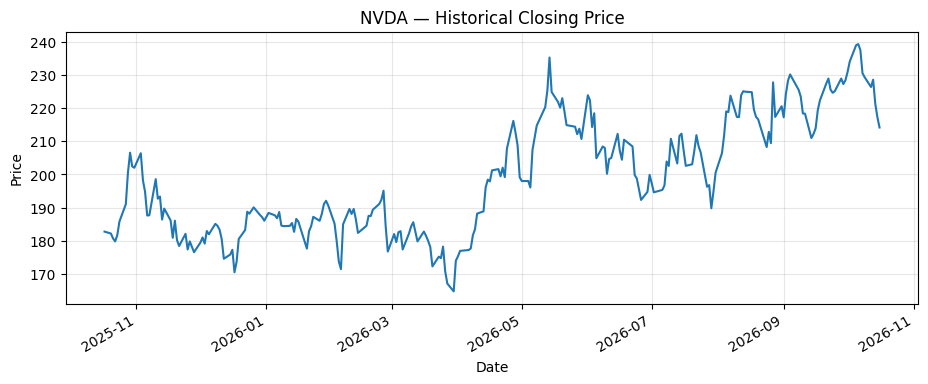

In [12]:
if "market" in research and isinstance(research["market"].get("history"), pd.DataFrame):
    hist = research["market"]["history"]
    col = "Adj Close" if "Adj Close" in hist.columns else "Close"
    hist[col].dropna().plot(figsize=(11, 4), title=f"{SYMBOL} — Historical Closing Price")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("Price chart unavailable; check data retrieval errors.")

### How to read the historical price chart

The chart visualizes the closing-price series retrieved for the selected ticker and period. The horizontal axis represents dates and the vertical axis represents the quoted price in the returned data's currency.

Use the chart to observe broad movements and changes in price levels. Do not interpret it as a prediction. The plot does not include a benchmark comparison, risk-adjusted performance, dividends, transaction costs, or a forecast model.

## 14. Workflow trace and memory verification

### Why the trace matters

The plan table shows the intended research steps; the tool-error table records exceptions; the evaluation table shows the score and feedback for each iteration; and the memory table shows saved notes. Together, these outputs provide an audit trail for the workflow.

An empty error table only means no exceptions were captured. It does not mean every field was returned, that the data was complete, or that the interpretation was correct. Always review the actual report and the availability flags as well as the exception log.

In [13]:
display(pd.DataFrame(research["plan"]))
print("Tool errors:")
display(pd.DataFrame(research.get("tool_errors", [])))
print("Evaluation history:")
display(pd.DataFrame([{"iteration": x["iteration"], "score": x["score_out_of_10"],
                       "feedback": x["feedback"]} for x in evaluation_history]))
print("Saved notes:")
display(pd.DataFrame(memory.retrieve(SYMBOL)))

,step,specialist,tool,purpose
0,1,market,history,Analyze historical price and returns
1,2,financial,company_info,Retrieve company profile and key metrics
2,3,financial,statements,Check financial statements
3,4,news,news,Process recent news headlines


Tool errors:


""


Evaluation history:


,iteration,score,feedback
0,1,8.3,[Add or verify discloses_missing_data]


Saved notes:


,timestamp_utc,evaluation_score,period_return_pct,news_count,tool_error_count,brief_note
0,2026-10-18T09:04:29.351534+00:00,8.3,17.150431,0,0,# Investment Research Summary: NVDA\nGenerated...
1,2026-10-18T09:11:40.814121+00:00,8.3,17.150421,0,0,# Investment Research Summary: NVDA\nGenerated...


### Interpretation of workflow trace and memory output

The workflow trace shows four planned tasks routed to their intended specialists: historical prices to the Market Agent, company information and statements to the Financial Agent, and news to the News Agent. The displayed empty tool-error table indicates that no exceptions were recorded in this run; it does not guarantee that every data field was populated.

The saved memory row records the run timestamp, evaluator score, period return, number of processed news articles, tool-error count, and a short report excerpt. This is the project's cross-run memory mechanism: the next run for the same ticker can retrieve the stored note. In this execution, the prior-memory count was zero before the first note was saved.

Because the news count was zero, this run's memory should not be treated as a complete research record. A future run should retry news retrieval or use another permitted source, then compare the new results with this saved note.

## 15. Basic tests
These tests use synthetic inputs and do not require another web request.

### Test coverage and remaining validation

The included tests cover planner task creation, invalid routing, news-chain processing on synthetic examples, and evaluator behavior on an incomplete report.

Additional recommended tests:
- Verify that market calculations are correct for a small hand-constructed price series.
- Test empty history, missing statement fields, and news records with unexpected schemas.
- Confirm that a failed tool call is reflected in the final report.
- Run the same ticker twice and verify that prior memory is retrieved.
- Compare a sample of company metrics with official company filings.
- Manually review real news classifications and report the agreement rate.

These tests would strengthen reliability beyond checking that the workflow runs.

In [14]:
assert [x["tool"] for x in planner.plan("AAPL")] == ["history", "company_info", "statements", "news"]
try:
    router.route({"step": 99, "specialist": "unknown"})
    raise AssertionError("Unknown route should fail")
except ValueError:
    pass

sample = [
    {"title": "Company reports strong revenue growth", "summary": "Revenue beats estimates by 12%",
     "publisher": "Example", "link": "https://example.com/1"},
    {"title": "Company faces lawsuit after weak quarter", "summary": "Shares fall 5%",
     "publisher": "Example", "link": "https://example.com/2"}
]
chain = news_agent.run_chain(sample, "NVDA")
assert chain["stage_counts"]["ingested"] == 2
assert chain["stage_counts"]["extracted"] == 2
assert chain["summary"]["news_count"] == 2
assert evaluator.evaluate("# Incomplete")["score_out_of_10"] < 8
print("All basic tests passed.")

All basic tests passed.


### Test results

The basic tests passed. They verify that:

1. The planner creates the expected four research steps.
2. The router rejects an unknown specialist instead of silently routing it.
3. The news prompt chain processes two synthetic example records through its stages.
4. The evaluator assigns a score below the threshold to an incomplete report.

These are **unit-style functional checks**, not a full validation of the financial data or news classification. The synthetic news test checks workflow behavior only; it does not establish the accuracy of the sentiment labels on real articles.

## 16. Evaluation, limitations, and conclusion

### Evaluation and iteration
The evaluator checks for required report sections and a missing-data disclosure. The optimizer adds follow-up items and a review note when the score is below the threshold. This is a deterministic quality-control loop, not a fact-checking guarantee.

### Learning across runs
The JSON memory stores timestamp, evaluation score, historical return, news count, tool errors, and a brief report excerpt per ticker. Later runs retrieve prior notes. This is persistent note-taking, not model training.

### Limitations and responsible use
- Yahoo Finance may omit fields, change schemas, or rate-limit requests.
- Rule-based news classification is a baseline and may misread negation or context.
- Ratios must be interpreted in sector and reporting-period context.
- The system does not execute trades; human review is required.
- Future improvements: SEC EDGAR filings, source citations for metrics, validated sentiment models, stronger tests, and human approval.

### Conclusion
This notebook demonstrates planning, dynamic tool use, specialist routing, news prompt chaining, report synthesis, evaluator–optimizer iteration, and persistent memory for investment research.

